In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
data = pd.read_csv("cifar-10.csv")

print("Dataset shape:", data.shape)

data.head()

Dataset shape: (50000, 3073)


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_3063,pixel_3064,pixel_3065,pixel_3066,pixel_3067,pixel_3068,pixel_3069,pixel_3070,pixel_3071,label
0,59,43,50,68,98,119,139,145,149,149,...,58,65,59,46,57,104,140,84,72,6
1,154,126,105,102,125,155,172,180,142,111,...,42,67,101,122,133,136,139,142,144,9
2,255,253,253,253,253,253,253,253,253,253,...,83,80,69,66,72,79,83,83,84,9
3,28,37,38,42,44,40,40,24,32,43,...,39,59,42,44,48,38,28,37,46,4
4,170,168,177,183,181,177,181,184,189,189,...,88,85,82,83,79,78,82,78,80,1


In [3]:
X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

print("Features shape:", X.shape)
print("Labels shape:", y.shape)

Features shape: (50000, 3072)
Labels shape: (50000,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (40000, 3072)
Testing data: (10000, 3072)


In [5]:
X_train = X_train / 255.0
X_test = X_test / 255.0

X_train = X_train.reshape(-1, 32, 32, 3)
X_test = X_test.reshape(-1, 32, 32, 3)

print("Training images shape:", X_train.shape)
print("Testing images shape:", X_test.shape)

Training images shape: (40000, 32, 32, 3)
Testing images shape: (10000, 32, 32, 3)


In [7]:
model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])



In [8]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [9]:
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 37s 32ms/step - accuracy: 0.4041 - loss: 1.6367 - val_accuracy: 0.5045 - val_loss: 1.3926
Epoch 2/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 38s 34ms/step - accuracy: 0.5333 - loss: 1.3035 - val_accuracy: 0.5720 - val_loss: 1.2266
Epoch 3/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 29s 26ms/step - accuracy: 0.5943 - loss: 1.1405 - val_accuracy: 0.5955 - val_loss: 1.1692
Epoch 4/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 32s 28ms/step - accuracy: 0.6349 - loss: 1.0259 - val_accuracy: 0.6062 - val_loss: 1.1448
Epoch 5/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 36s 24ms/step - accuracy: 0.6728 - loss: 0.9213 - val_accuracy: 0.6310 - val_loss: 1.0921
Epoch 6/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 46s 28ms/step - accuracy: 0.7078 - loss: 0.8290 - val_accuracy: 0.6185 - val_loss: 1.1403
Epoch 7/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 40s 28ms/step - accuracy: 0.7363 - loss: 0.7416 - val_accuracy: 0.6310 - val_loss: 1.1384
Epoch 8/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 43s 29ms/step - accuracy: 0.7646 -

In [10]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.6142 - loss: 1.3172
Test Loss: 1.3171745538711548
Test Accuracy: 61.41999959945679 %


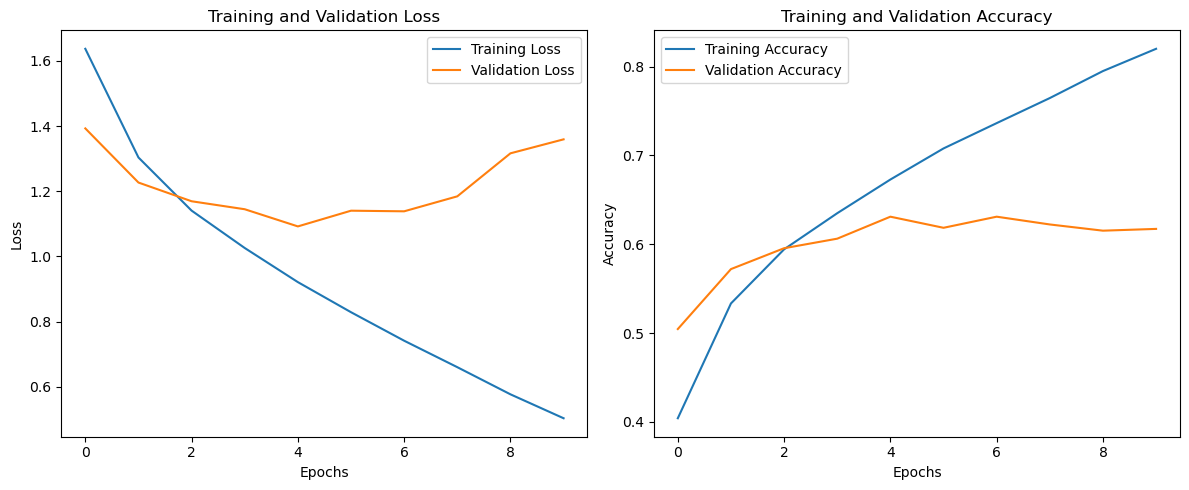

In [11]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()